<a href="https://colab.research.google.com/github/Andrew35780/dap-2024/blob/main/les08/lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №8. Кластеризация

Выполните следующие задания:

1. Откройте в файл в Google Colab (используйте собственный форк репозитория).
2. Решите задачи.
3. Сохраните результат в ваш репозиторий github в директорию ./les08
4. Создайте pull request в репозиторий https://github.com/chebotarevsa/dap-2024. Название pull request должно иметь формат "<Номер лабораторной работы>  <Номер группы> <ФИО>"
5. Сдайте работу в системе "Пегас", в отчет укажите ссылку на pull request

Ирисы Фишера — набор данных для задачи классификации, на примере которого Рональд Фишер в 1936 году продемонстрировал работу разработанного им метода дискриминантного анализа. Иногда его также называют ирисами Андерсона, так как данные были собраны американским ботаником Эдгаром Андерсоном.

In [2]:
import sys
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print(f"Python version: {sys.version}")
print(f"Numpy version: {np.version.version}")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {mpl.__version__}")

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Numpy version: 2.1.3
Pandas version: 2.2.3
Matplotlib version: 3.10.0


1. Импортируйте модель данных "Ирисы Фишера".

In [4]:
from sklearn.datasets import load_iris

iris = load_iris()

iris_df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

display(iris_df.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


2. Выполните нормализацию данных

In [6]:
# Импортируем необходимый класс из модуля preprocessing библиотеки sklearn
from sklearn.preprocessing import StandardScaler

# Создадим объект этого класса
scaler = StandardScaler()

# Приведем данные к единому масштабу
iris_scaled = scaler.fit_transform(iris_df)

# Заново создадим датафрейм с нормализованными значениями
iris_df_scaled = pd.DataFrame(iris_scaled, columns = iris.feature_names)

# посмотрим на первые пять строк
iris_df_scaled.round(2).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.90,1.02,-1.34,-1.32
1,-1.14,-0.13,-1.34,-1.32
2,-1.39,0.33,-1.40,-1.32
3,-1.51,0.10,-1.28,-1.32
4,-1.02,1.25,-1.34,-1.32


3. Постройте модель кластеризации используя алгоритм  DBSCAN (https://www.youtube.com/watch?v=svAtnZ5XjSI&t=494s), подберите подходящие параметры eps, min_samples

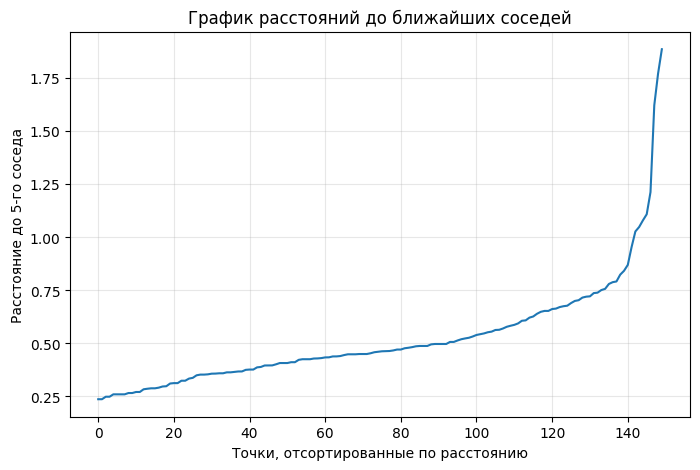

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

k = 5

neighbors = NearestNeighbors(n_neighbors=k)

neighbors.fit(iris_scaled)

distances, indices = neighbors.kneighbors(iris_scaled)

k_distances = np.sort(distances[:, k - 1])

plt.figure(figsize=(8, 5))

plt.plot(k_distances)

plt.xlabel("Точки, отсортированные по расстоянию")
plt.ylabel("Расстояние до 5-го соседа")
plt.title("График расстояний до ближайших соседей")

plt.grid(alpha=0.3)
plt.show()

In [18]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import silhouette_score
from sklearn.cluster import DBSCAN

eps_values = np.arange(0.3, 1.05, 0.05).round(2)
min_samples_values = range(3, 11)

results = []
for eps in eps_values:
    for ms in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(iris_scaled)
        mask = labels != -1
        n_clusters = len(set(labels[mask]))
        sil = (silhouette_score(iris_scaled[mask], labels[mask])
               if n_clusters >= 2 else np.nan)
        results.append({
            "eps": eps, "min_samples": ms,
            "n_clusters": n_clusters,
            "noise_share": (~mask).mean().round(3),
            "silhouette": sil,
            "ARI": adjusted_rand_score(iris.target, labels),
        })

results_df = pd.DataFrame(results)
display(results_df[results_df.noise_share <= 0.15]
        .sort_values("silhouette", ascending=False))

,eps,min_samples,n_clusters,noise_share,silhouette,ARI
59,0.65,6,2,0.127,0.633404,0.484909
70,0.70,9,2,0.133,0.629096,0.494391
71,0.70,10,2,0.133,0.629096,0.494391
69,0.70,8,2,0.113,0.626692,0.500805
68,0.70,7,2,0.107,0.625464,0.505269
...,...,...,...,...,...,...
49,0.60,4,3,0.127,0.546864,0.485412
56,0.65,3,3,0.047,0.417440,0.536755
48,0.60,3,4,0.060,0.345171,0.523858
40,0.55,3,5,0.093,0.302128,0.469513


4. Постройте диаграмму рассеяния для признаков "sepal length (cm)" "sepal width (cm)", цвет точек на диаграмме должен быть различным для разных кластеров

На диаграмме откладываем исходные значения признаков, а не нормализованные, чтобы оси были в сантиметрах.

In [19]:
model = DBSCAN(eps=0.85, min_samples=5)
labels = model.fit_predict(iris_scaled)

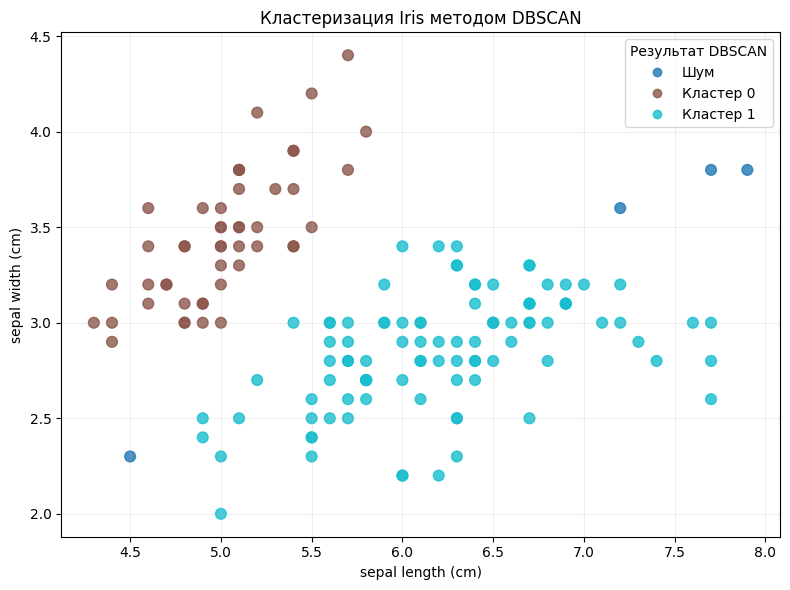

In [15]:
fig, ax = plt.subplots(figsize=(8, 6))

scatter = ax.scatter(
    iris.data[:, 0],
    iris.data[:, 1],
    c=labels,
    cmap="tab10",
    s=60,
    alpha=0.8
)

ax.set_xlabel(iris.feature_names[0])
ax.set_ylabel(iris.feature_names[1])

ax.set_title("Кластеризация Iris методом DBSCAN")

handles, _ = scatter.legend_elements()

legend_labels = []

for cluster_id in np.unique(labels):
    if cluster_id == -1:
        legend_labels.append("Шум")
    else:
        legend_labels.append(f"Кластер {cluster_id}")

ax.legend(handles, legend_labels, title="Результат DBSCAN")

ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

5. Сделайте вывод

В ходе лабораторной работы был загружен набор данных Iris, содержащий
150 образцов и 4 признака каждого цветка.

Перед кластеризацией данные были нормализованы с помощью StandardScaler,
чтобы признаки имели сопоставимый масштаб.

Для выбора параметров DBSCAN был построен график расстояний до ближайших
соседей и выполнено сравнение нескольких комбинаций eps и min_samples.

Параметры DBSCAN подбирались перебором eps ∈ [0.3; 1.0] и min_samples ∈ [3; 10] по графику k-расстояний с оценкой silhouette (без шума), доли шума и ARI.

Наибольший silhouette (0.633) у eps=0.65, но при доле шума 12.7%.

Выбрана пара eps=0.85, min_samples=5: она лежит в устойчивой области, где результат не меняется, и даёт silhouette 0.598 при 2.7% шума.

Алгоритм выделил два кластера: setosa и объединённые versicolor и virginica, которые пересекаются по признакам.

Конфигурация с тремя кластерами (eps=0.6, min_samples=4) формально совпадает с числом видов, но хуже по всем метрикам и отбрасывает 12.7% точек в шум. DBSCAN плотностной алгоритм, и на данных с частично перекрывающимися классами он не может их разделить.

На диаграмме рассеяния показано распределение найденных кластеров по
признакам sepal length и sepal width.

В результате работы были изучены принципы кластеризации
и влияние параметров eps и min_samples на результат.

## Вопросы


### 1. В чём состоит задача кластеризации?

Кластеризация — это задача машинного обучения без учителя, в которой
объекты группируются по сходству их характеристик.

Алгоритму не сообщают заранее правильные группы объектов. Он пытается
самостоятельно найти структуру в данных.

В лабораторной работе DBSCAN группирует ирисы по четырём измеренным
характеристикам цветков.

### 2. Для каких целей используется кластеризация?

Кластеризация используется для поиска групп похожих объектов, изучения
структуры данных и выявления необычных наблюдений.

Примеры применения:
- сегментация покупателей по поведению;
- группировка документов по содержанию;
- обнаружение необычных сетевых подключений;
- исследование похожих биологических образцов.

Кластеризация может помогать в анализе данных, но найденные группы
не обязательно совпадают с заранее известными категориями.

### 3. Алгоритм кластеризации Ллойда

Алгоритм Ллойда обычно используется для решения задачи K-средних (K-means).

Основные шаги:
1. Выбирается количество кластеров K.
2. Инициализируются центры кластеров.
3. Каждая точка относится к ближайшему центру.
4. Для каждого кластера вычисляется новый центр как среднее положение
   входящих в него точек.
5. Шаги назначения точек и пересчёта центров повторяются до остановки.

Алгоритм стремится уменьшить сумму квадратов расстояний от точек
до центров своих кластеров.

### 4. Как выбрать количество кластеров для алгоритма K-средних?

Количество кластеров K задаётся до запуска K-means.

Для его выбора могут использоваться:
- метод локтя — ищут момент, после которого увеличение K даёт
  всё меньшее улучшение компактности кластеров;
- силуэтная оценка — помогает оценить разделённость кластеров;
- предметные знания — например, если заранее известно, какие группы
  нужны для решения задачи.

Ни один из этих методов не гарантирует единственно правильного K.
Результат необходимо интерпретировать с учётом задачи.

### 5. Алгоритм DBSCAN

DBSCAN — алгоритм кластеризации, который находит группы объектов
по плотности их расположения.

У него два основных параметра:
- `eps` — радиус окрестности точки;
- `min_samples` — минимальное количество точек в окрестности,
  необходимое для того, чтобы точка считалась основной.

DBSCAN может находить кластеры произвольной формы и выделять шумовые
точки, которые не относятся к плотным группам.

В отличие от K-means, DBSCAN не требует заранее задавать количество
кластеров.

Результат зависит от выбора `eps` и `min_samples`. Если параметры
подобраны неудачно, алгоритм может объединить разные группы,
разделить одну группу или объявить много точек шумом.